In [3]:
import random

import numpy as np
import pandas as pd
import scipy.stats

In [4]:
DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
MIXMHCPRED_DATA_EXTERNAL_PATH = f'{DATA_PATH_BASE}/Binding data/MixMHC2pred/train_data/external_studies.csv'
MIXMHCPRED_DATA_INHOUSE_PATH = f'{DATA_PATH_BASE}/Binding data/MixMHC2pred/train_data/current_study.csv'


## Read the data

In [5]:
df_external = pd.read_csv(MIXMHCPRED_DATA_EXTERNAL_PATH,sep=";")
df_external.columns = list(map(str.lower, df_external.columns))
df_inhouse = pd.read_csv(MIXMHCPRED_DATA_INHOUSE_PATH,sep=";")
df_inhouse.columns = list(map(str.lower, df_inhouse.columns))

FileNotFoundError: [Errno 2] No such file or directory: 'G:/My Drive/Work/ITMO/data/Binding data/MixMHC2pred/train_data/external_studies.csv'

## Keep only with cores known and length of core == 9

In [4]:
df_external = df_external[df_external.core.str.len() > 0]
df_inhouse = df_inhouse[df_inhouse.core.str.len() > 0]
df_external['core_len'] = df_external.core.str.len()
df_inhouse['core_len'] = df_inhouse.core.str.len()
df_external = df_external[df_external.core_len == 9]
df_external = df_external[~df_external.allele.str.contains(" or ")]
df_external = df_external[~df_external.allele.str.contains("Contamination")]

df_inhouse = df_inhouse[df_inhouse.core_len == 9]
df_inhouse = df_inhouse[~df_inhouse.allele.str.contains(" or ")]
df_inhouse = df_inhouse[~df_inhouse.allele.str.contains("Contamination")]



## Distribution of alleles

In [5]:
len(df_external)

609500

In [6]:
len(df_external.allele.unique())

86

In [7]:
df_external.allele.value_counts()

DRB1*12:01               42661
DRB1*01:01               28715
DRB1*11:01               25394
DRB3*02:02               21790
DRB1*07:01               20086
                         ...  
DQA1*03:01/DQB1*03:01      561
H2-IEd                     449
DRB1*16:02                 411
DQA1*01:01/DQB1*06:02      319
DQA1*01:01/DQB1*05:01       73
Name: allele, Length: 86, dtype: int64

In [8]:
", ".join(list(df_external.columns))

'peptide, pepl, genename, nterm, cterm, sample_ids, allele, multispec, core, coreoffset, core_len'

## Make logo for specific allele

In [9]:
import seaborn as sns
import logomaker
def make_logo_for_data(binders_array, name, ax=None):
    sns.set_theme(style="white")
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True, ax=ax)
    ww_logo.ax.set_title(f"{name}, {len(binders_array)}")

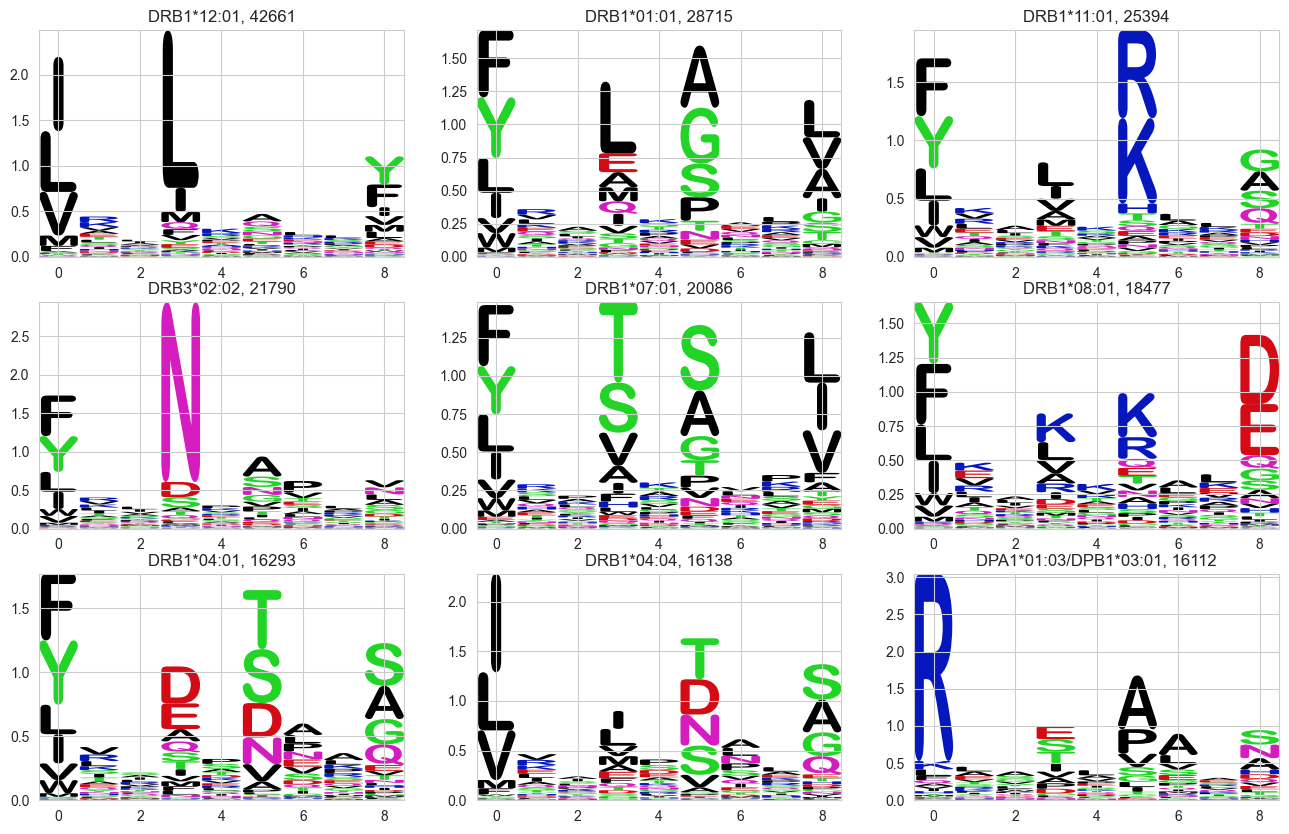

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3,3, figsize=(16,10))

make_logo_for_data(df_external[df_external.allele == 'DRB1*12:01'].core.values, "DRB1*12:01", ax=axes[0,0])
make_logo_for_data(df_external[df_external.allele == 'DRB1*01:01'].core.values, "DRB1*01:01",ax=axes[0,1])
make_logo_for_data(df_external[df_external.allele == 'DRB1*11:01'].core.values, "DRB1*11:01",ax=axes[0,2])
make_logo_for_data(df_external[df_external.allele == 'DRB3*02:02'].core.values, "DRB3*02:02", ax=axes[1,0])
make_logo_for_data(df_external[df_external.allele == 'DRB1*07:01'].core.values, "DRB1*07:01", ax=axes[1,1])
make_logo_for_data(df_external[df_external.allele == 'DRB1*08:01'].core.values, "DRB1*08:01", ax=axes[1,2])
make_logo_for_data(df_external[df_external.allele == 'DRB1*04:01'].core.values, "DRB1*04:01", ax=axes[2,0])
make_logo_for_data(df_external[df_external.allele == 'DRB1*04:04'].core.values, "DRB1*04:04", ax=axes[2,1])
make_logo_for_data(df_external[df_external.allele == 'DPA1*01:03/DPB1*03:01'].core.values, "DPA1*01:03/DPB1*03:01", ax=axes[2,2])


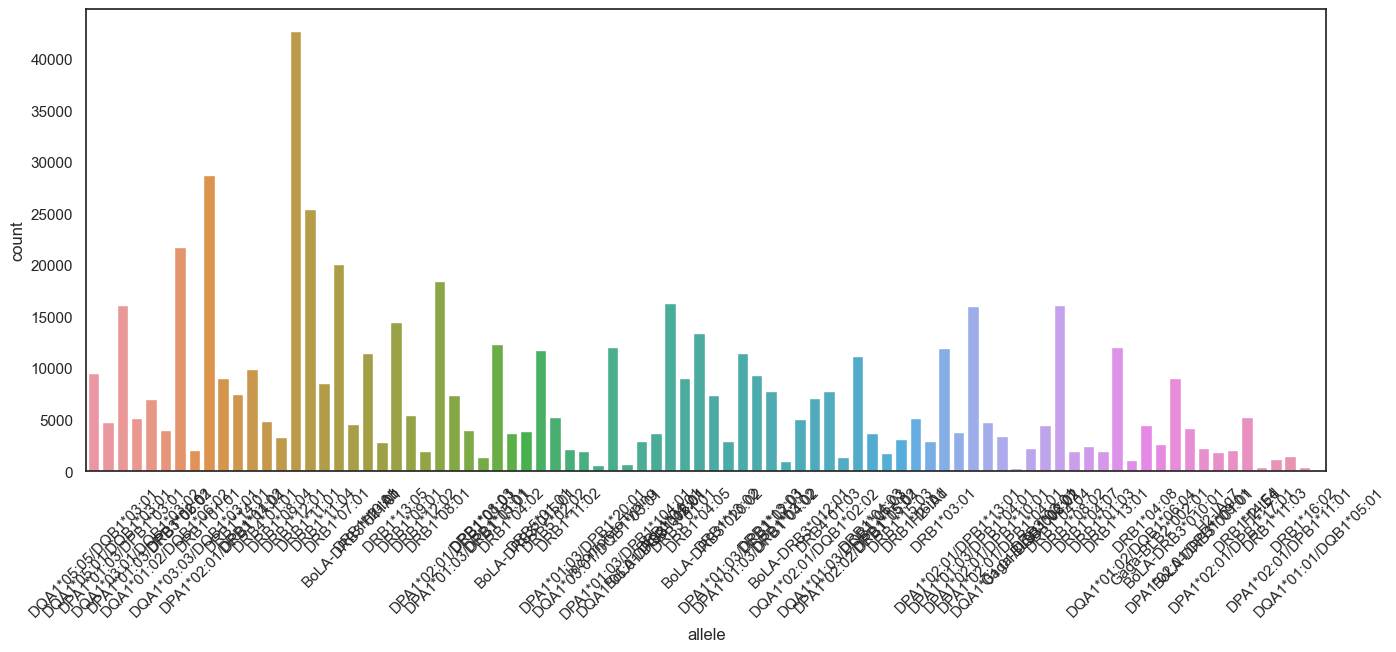

In [11]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(16, 6))
_ = sns.countplot(df_external, x='allele',ax=ax).set_xticklabels(ax.get_xticklabels(), rotation=45)


# Get decoy data with fake cores

In [12]:
class_to_use = 'II'
organism = 'Human'
DECOY_DATA_PATH = f"{DATA_PATH_BASE}\decoy\sampled_decoy_data_{organism}_class_{class_to_use}.csv"
decoy_df =  pd.read_csv(DECOY_DATA_PATH)

In [13]:
decoy_df =decoy_df.iloc[:int(len(decoy_df)/12000)*12000]
decoy_df['core'] = decoy_df.peptide.str.slice(0,9)
decoy_df['core_len'] = decoy_df.core.str.len()
decoy_df['allele'] = [ f'decoy_allele_{j}'  for j in range(int(len(decoy_df)/12000)) for i in range(12000)]

In [14]:
len(decoy_df)

3396000

In [15]:
len(decoy_df.allele.unique())

283

In [16]:
decoy_df.allele.value_counts()

decoy_allele_0      12000
decoy_allele_186    12000
decoy_allele_192    12000
decoy_allele_191    12000
decoy_allele_190    12000
                    ...  
decoy_allele_100    12000
decoy_allele_101    12000
decoy_allele_102    12000
decoy_allele_103    12000
decoy_allele_282    12000
Name: allele, Length: 283, dtype: int64

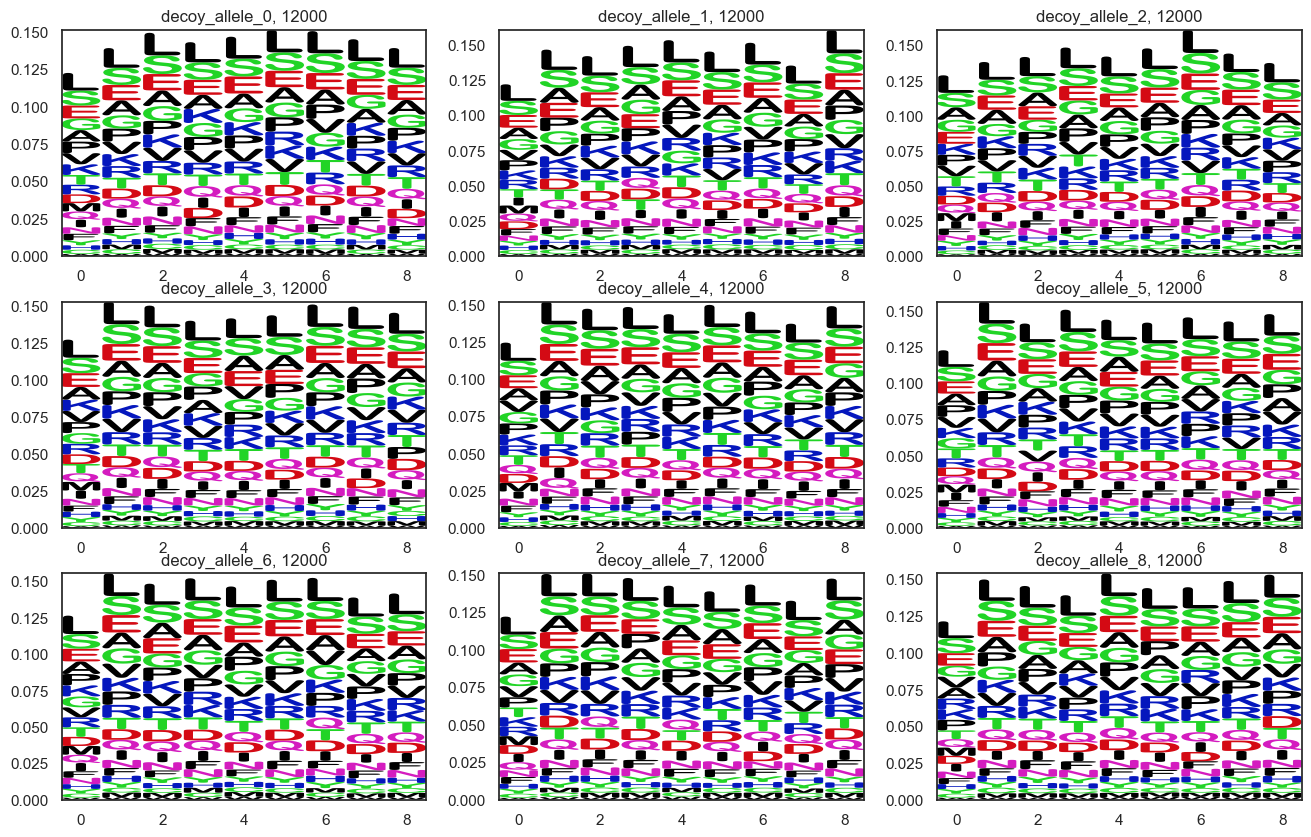

In [17]:
fig, axes = plt.subplots(3,3, figsize=(16,10))

make_logo_for_data(decoy_df[decoy_df.allele == 'decoy_allele_0'].core.values, "decoy_allele_0", ax=axes[0,0])
make_logo_for_data(decoy_df[decoy_df.allele == 'decoy_allele_1'].core.values, "decoy_allele_1",ax=axes[0,1])
make_logo_for_data(decoy_df[decoy_df.allele == 'decoy_allele_2'].core.values, "decoy_allele_2",ax=axes[0,2])
make_logo_for_data(decoy_df[decoy_df.allele == 'decoy_allele_3'].core.values, "decoy_allele_3", ax=axes[1,0])
make_logo_for_data(decoy_df[decoy_df.allele == 'decoy_allele_4'].core.values, "decoy_allele_4", ax=axes[1,1])
make_logo_for_data(decoy_df[decoy_df.allele == 'decoy_allele_5'].core.values, "decoy_allele_5", ax=axes[1,2])
make_logo_for_data(decoy_df[decoy_df.allele == 'decoy_allele_6'].core.values, "decoy_allele_6", ax=axes[2,0])
make_logo_for_data(decoy_df[decoy_df.allele == 'decoy_allele_7'].core.values, "decoy_allele_7", ax=axes[2,1])
make_logo_for_data(decoy_df[decoy_df.allele == 'decoy_allele_8'].core.values, "decoy_allele_8", ax=axes[2,2])

In [18]:
natural_distribution_of_aas = logomaker.alignment_to_matrix(decoy_df.core.values, to_type='probability')

In [19]:
natural_distribution_of_aas

,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
pos,,,,,,,,,,,,,,,,,,,,
0,0.066470,0.021098,0.047650,0.070905,0.035178,0.062337,0.025244,0.043243,0.057427,0.096161,0.048262,0.035963,0.059660,0.046936,0.054387,0.080709,0.052072,0.058573,0.011643,0.026081
1,0.072670,0.021394,0.049358,0.073551,0.035895,0.064253,0.025589,0.043923,0.058732,0.097830,0.020121,0.036813,0.061120,0.048146,0.055557,0.083785,0.052932,0.059797,0.012136,0.026400
2,0.069118,0.021588,0.048783,0.073203,0.036093,0.064614,0.025921,0.044076,0.058688,0.098571,0.020067,0.037057,0.061907,0.048493,0.056557,0.083373,0.053571,0.059865,0.012002,0.026451
3,0.068862,0.021655,0.048610,0.072794,0.036279,0.064313,0.025824,0.044254,0.059194,0.098881,0.019957,0.036961,0.062012,0.048469,0.056567,0.083277,0.053352,0.060036,0.012122,0.026580
4,0.068845,0.021720,0.048782,0.072919,0.036159,0.064450,0.025756,0.044398,0.059172,0.098939,0.020192,0.036688,0.061690,0.048499,0.056249,0.083137,0.053281,0.060281,0.012219,0.026624
5,0.068659,0.021726,0.048920,0.072867,0.036002,0.064652,0.025919,0.044235,0.059002,0.099314,0.020052,0.036728,0.061724,0.048412,0.056468,0.083329,0.053338,0.059835,0.012190,0.026628
6,0.068586,0.021613,0.048698,0.073018,0.036042,0.064504,0.026101,0.044385,0.058796,0.099350,0.020060,0.036957,0.061657,0.048323,0.056445,0.082763,0.053580,0.060264,0.012032,0.026825
7,0.068583,0.021718,0.048702,0.072810,0.036168,0.064363,0.026049,0.044105,0.058974,0.099163,0.020091,0.036816,0.061886,0.048507,0.056477,0.083116,0.053370,0.060089,0.012238,0.026777
8,0.068831,0.021862,0.048880,0.072515,0.036077,0.064294,0.026190,0.044410,0.058693,0.099245,0.020075,0.036795,0.061539,0.048605,0.056547,0.082922,0.053510,0.060297,0.012115,0.026599


## Generate simulated data

In [20]:
import numpy as np
from tqdm import tqdm
from numpy.random import default_rng
# generate a lot of data

rng = default_rng()
set1 = ['A', 'C', 'D', 'E', 'F', 'G', 'H', 'I','K', 'L']
set2 = ['M', 'N', 'P', 'Q','R', 'S', 'T', 'V', 'W', 'Y']

total_set = set1 + set2

motifs_sequences = list()
number_of_anchors_list = list()
set_group = list()
simulated_alleles = list()
len_of_each_motif = 12000

for i in tqdm(range(1000)):
    number_of_anchors = rng.choice(np.arange(1,10))
    positions = rng.choice(9, size=number_of_anchors, replace=False)
    sequences_array = np.empty((len_of_each_motif,9), dtype=str)
    for anchor_position in positions:
        acids_to_use = rng.choice(np.arange(1, len(set1) + 1))
        probabilities = np.random.random_sample(acids_to_use)
        probabilities = probabilities/sum(probabilities)
        anchor_acids = rng.choice(set1, size=acids_to_use)
        sequences_array[:, anchor_position] = rng.choice(anchor_acids, sequences_array.shape[0], p=probabilities)
    sequences_array[sequences_array == ''] = np.random.choice(total_set, len(sequences_array[sequences_array == '']),p=list(natural_distribution_of_aas.loc[0]))
    motifs_sequences.append(["".join(item) for item in sequences_array])
    number_of_anchors_list.append(number_of_anchors)
    simulated_alleles.append(f"allele_{i}")

for i in tqdm(range(1000)):
    number_of_anchors = rng.choice(np.arange(1,10))
    positions = rng.choice(9, size=number_of_anchors, replace=False)
    sequences_array = np.empty((len_of_each_motif,9), dtype=str)
    for anchor_position in positions:
        acids_to_use = rng.choice(np.arange(1, len(set2) + 1))
        probabilities = np.random.random_sample(acids_to_use)
        probabilities = probabilities/sum(probabilities)
        anchor_acids = rng.choice(set2, size=acids_to_use)
        sequences_array[:, anchor_position] = rng.choice(anchor_acids, sequences_array.shape[0], p=probabilities)
    sequences_array[sequences_array == ''] = np.random.choice(total_set, len(sequences_array[sequences_array == '']), p=list(natural_distribution_of_aas.loc[0]))
    motifs_sequences.append(["".join(item) for item in sequences_array])
    number_of_anchors_list.append(number_of_anchors)
    simulated_alleles.append(f"allele_{i+1000}")

for i in tqdm(range(1000)):
    number_of_anchors = rng.choice(np.arange(1,10))
    positions = rng.choice(9, size=number_of_anchors, replace=False)
    sequences_array = np.empty((len_of_each_motif,9), dtype=str)
    for anchor_position in positions:
        acids_to_use = rng.choice(np.arange(1, len(total_set) + 1))
        probabilities = np.random.random_sample(acids_to_use)
        probabilities = probabilities/sum(probabilities)
        anchor_acids = rng.choice(total_set, size=acids_to_use)
        sequences_array[:, anchor_position] = rng.choice(anchor_acids, sequences_array.shape[0], p=probabilities)
    sequences_array[sequences_array == ''] = np.random.choice(total_set, len(sequences_array[sequences_array == '']),p=list(natural_distribution_of_aas.loc[0]))
    motifs_sequences.append(["".join(item) for item in sequences_array])
    number_of_anchors_list.append(number_of_anchors)
    simulated_alleles.append(f"allele_{i+2000}")


simulated_allele_to_matrix = dict()
for i in tqdm(range(len(motifs_sequences))):
    sequences = motifs_sequences[i]
    cur_matrix = logomaker.alignment_to_matrix(sequences, to_type='probability')
    for column in natural_distribution_of_aas:
        if column not in cur_matrix:
            cur_matrix[column] = 0
    simulated_allele_to_matrix[simulated_alleles[i]] = cur_matrix[natural_distribution_of_aas.columns]

100%|██████████| 3000/3000 [03:55<00:00, 12.73it/s]


In [21]:
simulated_annotation = pd.DataFrame({"allele": simulated_alleles, "number_of_anchors":number_of_anchors_list, "index_in_list": np.arange(len(simulated_alleles))})

In [22]:
for number_of_anchors in range(1,10):
    print("Number of anchors =", number_of_anchors, ":", len(simulated_annotation[simulated_annotation.number_of_anchors == number_of_anchors]))

Number of anchors = 1 : 334
Number of anchors = 2 : 337
Number of anchors = 3 : 305
Number of anchors = 4 : 322
Number of anchors = 5 : 342
Number of anchors = 6 : 343
Number of anchors = 7 : 353
Number of anchors = 8 : 323
Number of anchors = 9 : 341


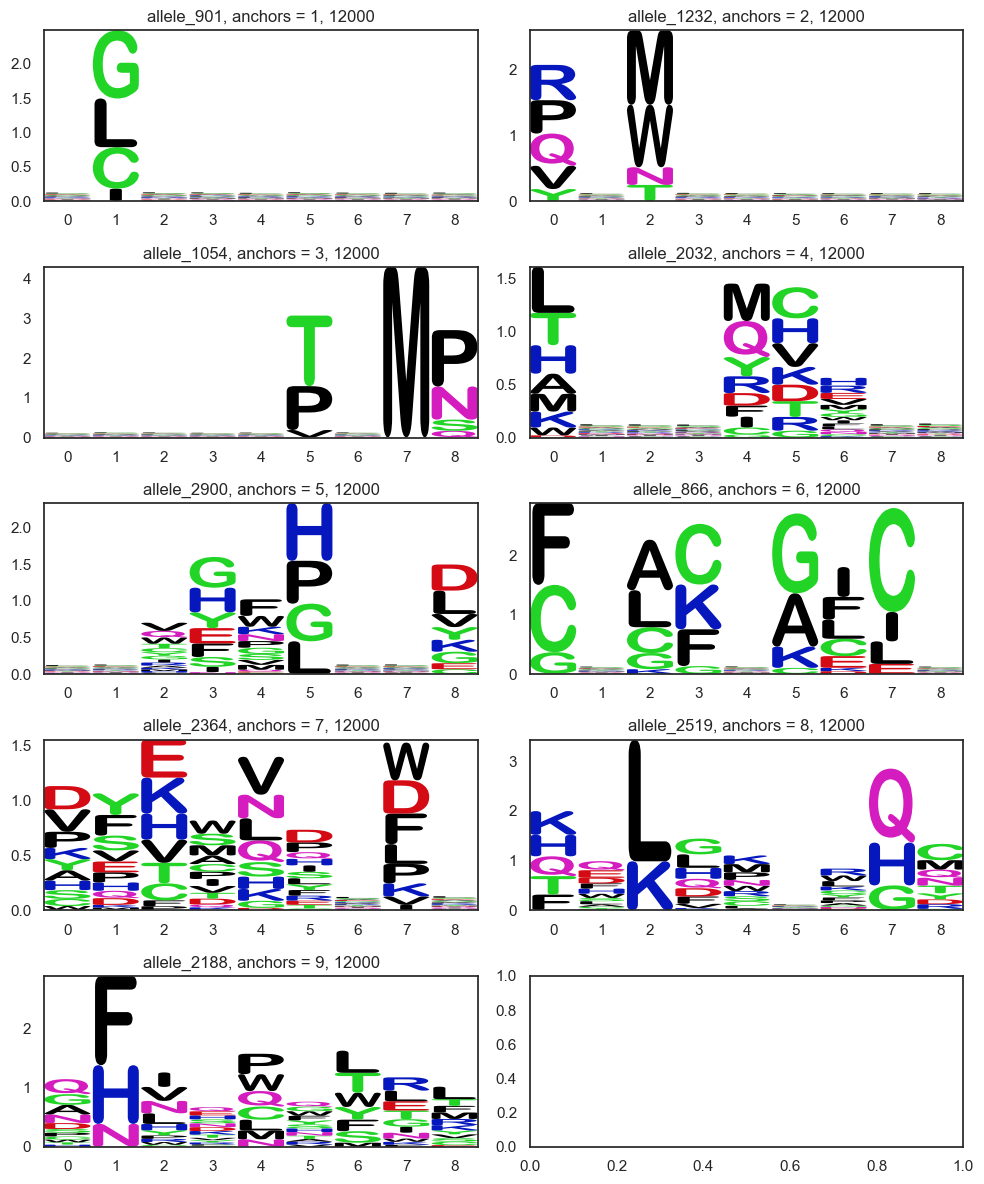

In [23]:
fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(10, 12))
for number_of_anchors, ax_index in zip(range(1,10), np.ndindex(axes.shape)):
    index_of_data = simulated_annotation[simulated_annotation.number_of_anchors == number_of_anchors]['index_in_list'].sample().iloc[0]
    make_logo_for_data(motifs_sequences[index_of_data], f"{simulated_alleles[index_of_data]}, anchors = {number_of_anchors}", ax=axes[ax_index])
plt.tight_layout()

# Transfrom data cores to Matrix with distributions (similarly as we did for simulated data)

In [24]:
alleles_external = df_external.allele.unique()

In [25]:
allele_to_matrix = dict()
from tqdm import tqdm
for allele_name in tqdm(alleles_external):
    cur_matrix = logomaker.alignment_to_matrix(df_external[df_external.allele == allele_name].core.values, to_type='probability')

    for column in natural_distribution_of_aas:
        if column not in cur_matrix:
            cur_matrix[column] = 0
    allele_to_matrix[allele_name] = cur_matrix[natural_distribution_of_aas.columns]


alleles_decoy = decoy_df.allele.unique()
decoy_allele_to_matrix = dict()
for allele_name in tqdm(alleles_decoy):
    cur_matrix = logomaker.alignment_to_matrix(decoy_df[decoy_df.allele == allele_name].core.values, to_type='probability')

    for column in natural_distribution_of_aas:
        if column not in cur_matrix:
            cur_matrix[column] = 0
    decoy_allele_to_matrix[allele_name] = cur_matrix[natural_distribution_of_aas.columns]

100%|██████████| 283/283 [01:21<00:00,  3.45it/s]


## Get information vectors for each of the alleles

In [26]:
%%time
external_allele_to_info_vector = {allele_name: logomaker.transform_matrix(prob_matrix,
                                                                 from_type='probability',
                                                                 to_type='information',
                                                                 background=natural_distribution_of_aas.copy()).sum(axis=1).values  for allele_name, prob_matrix in allele_to_matrix.items()}

decoy_allele_to_info_vector = {allele_name: logomaker.transform_matrix(prob_matrix,
                                                                 from_type='probability',
                                                                 to_type='information',
                                                                 background=natural_distribution_of_aas.copy()).sum(axis=1).values  for allele_name, prob_matrix in decoy_allele_to_matrix.items()}

simulated_allele_to_info_vector = {allele_name: logomaker.transform_matrix(prob_matrix,
                                                                 from_type='probability',
                                                                 to_type='information',
                                                                 background=natural_distribution_of_aas.copy()).sum(axis=1).values  for allele_name, prob_matrix in simulated_allele_to_matrix.items()}

CPU times: total: 18.5 s
Wall time: 19.5 s


In [27]:
external_mean_informations = [sum(item)/len(item) for item in external_allele_to_info_vector.values()]
decoy_mean_informations = [sum(item)/len(item) for item in decoy_allele_to_info_vector.values()]
simulated_mean_informations = [sum(item)/len(item) for item in simulated_allele_to_info_vector.values()]

## Now we want to plot distributions of these values.
we will do dataframe with these values and some annotations

In [31]:
import seaborn as sns

In [32]:
df_external_info = pd.DataFrame({"allele":external_allele_to_info_vector.keys(), "mean_information":external_mean_informations, 'allele_type':'real_data'})

df_decoy_info = pd.DataFrame({"allele":decoy_allele_to_info_vector.keys(), "mean_information":decoy_mean_informations,'allele_type':'decoy'})

simulated_dfs = list()

for number_of_anchors in range(1,10):
    current_alleles_indexes = list(simulated_annotation[simulated_annotation.number_of_anchors == number_of_anchors].index_in_list)
    current_allele_names = np.array(simulated_alleles)[current_alleles_indexes]
    current_information = np.array(simulated_mean_informations)[current_alleles_indexes]
    current_allele_type = f"simulated_anchors={number_of_anchors}"
    current_df_info = pd.DataFrame({"allele":current_allele_names, "mean_information":current_information,'allele_type':current_allele_type})
    simulated_dfs.append(current_df_info)


In [49]:
total_df=pd.concat([df_external_info,df_decoy_info] + simulated_dfs)
total_df = total_df[total_df.allele != 'Incomplete typing']

Get minimum and maximum for each group

In [51]:
total_df.groupby('allele_type').min('mean_information')

,mean_information
allele_type,
decoy,0.000856
real_data,0.444539
simulated_anchors=1,0.092070
simulated_anchors=2,0.242569
simulated_anchors=3,0.336267
simulated_anchors=4,0.472415
simulated_anchors=5,0.664126
simulated_anchors=6,0.739405
simulated_anchors=7,1.025339


In [52]:
total_df.groupby('allele_type').max('mean_information')

,mean_information
allele_type,
decoy,0.001552
real_data,1.267348
simulated_anchors=1,0.722498
simulated_anchors=2,1.173092
simulated_anchors=3,1.632276
simulated_anchors=4,1.942276
simulated_anchors=5,2.196600
simulated_anchors=6,2.508114
simulated_anchors=7,3.315738


### Plot distributions
#### For simulated data

Text(0.5, 1.0, 'Information content per position for cores')

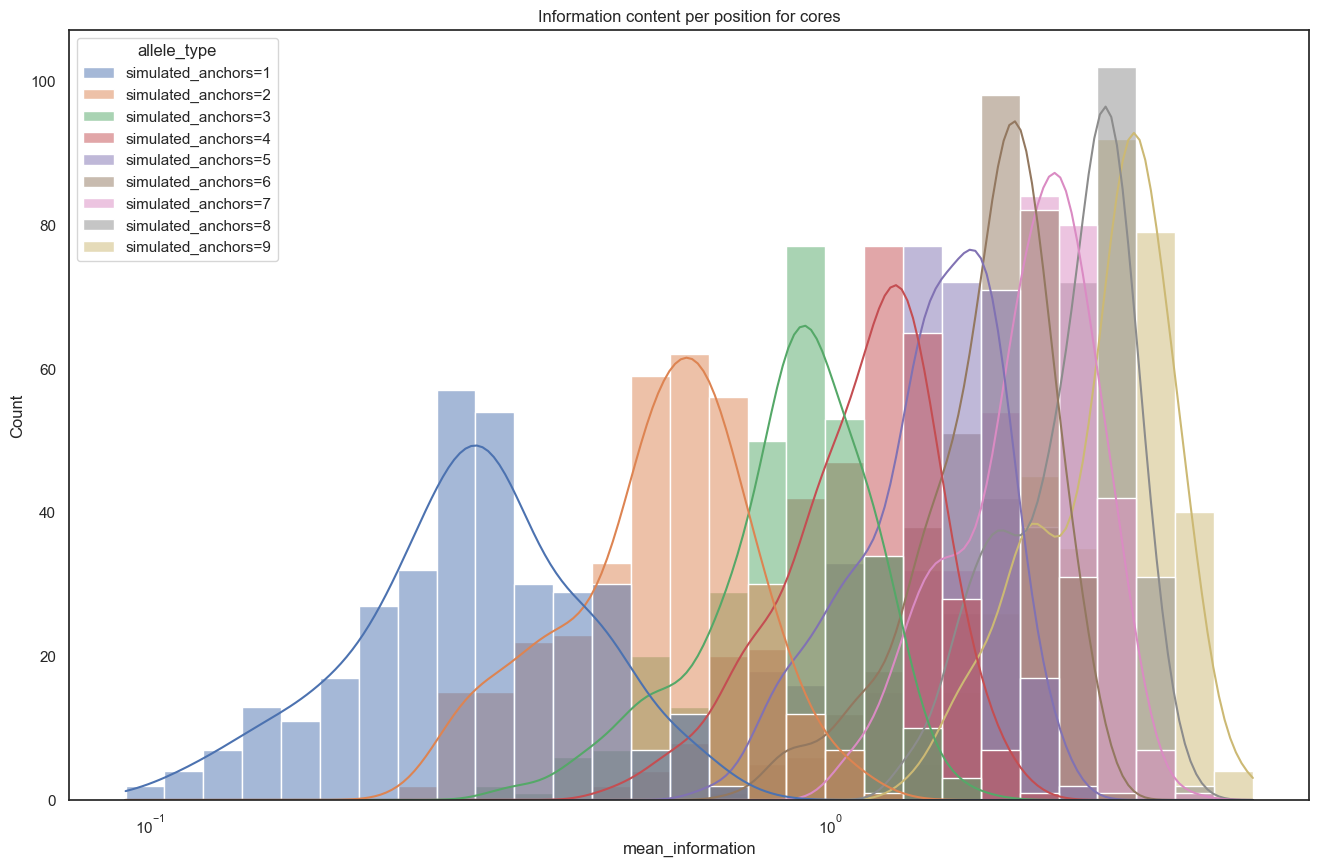

In [53]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(16, 10))
sns.histplot(total_df[total_df.allele_type.str.startswith('simulated')],kde=True, x='mean_information', hue='allele_type', log_scale=True, ax=ax)
ax.set_title('Information content per position for cores')

#### Add real data

Text(0.5, 1.0, 'Information content per position for cores')

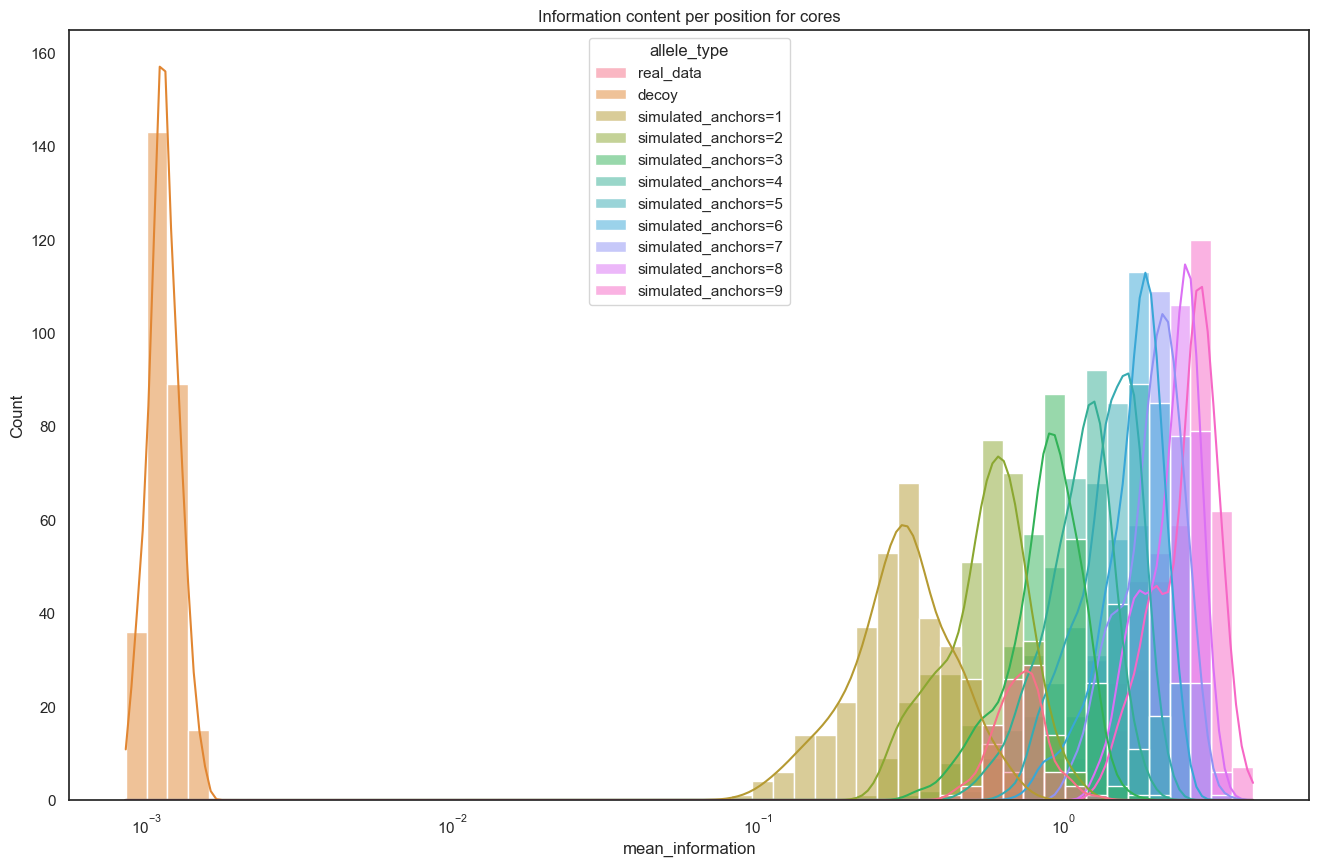

In [54]:
# total data
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(16, 10))
sns.histplot(total_df,kde=True, x='mean_information', hue='allele_type', log_scale=True, ax=ax)
ax.set_title('Information content per position for cores')

## Plot motifs for some low and high values

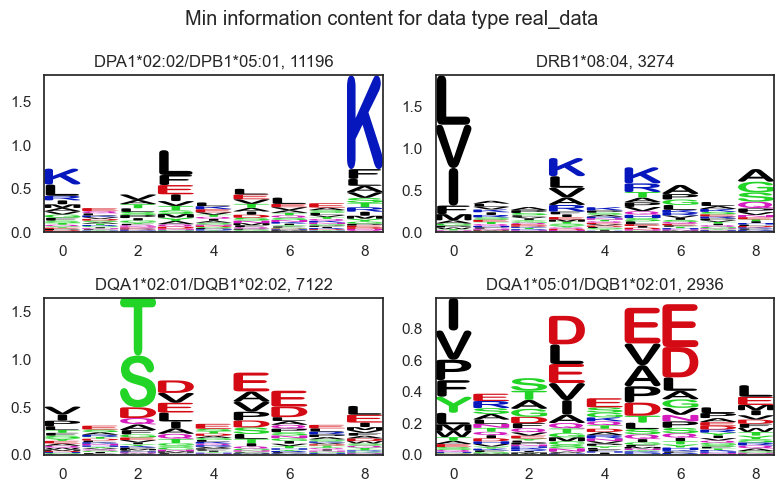

In [57]:
allele_type = 'real_data'
number_of_motifs = 4


fig, axes = plt.subplots(nrows=int(number_of_motifs/2), ncols=2, figsize=(8, 5))
max_alleles = total_df[total_df.allele_type == allele_type].sort_values(by='mean_information', ascending=True).head(number_of_motifs).allele.values
for allele, ax_ind in zip(max_alleles, np.ndindex(axes.shape)):
    make_logo_for_data(df_external[df_external.allele == allele].core.values, allele, ax=axes[ax_ind])

fig.suptitle(f"Min information content for data type {allele_type}")
plt.tight_layout()


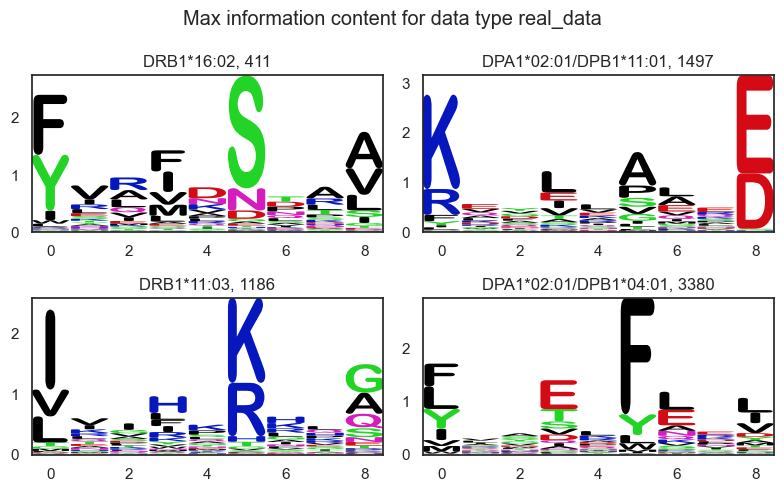

In [59]:
allele_type = 'real_data'
number_of_motifs = 4


fig, axes = plt.subplots(nrows=int(number_of_motifs/2), ncols=2, figsize=(8, 5))
max_alleles = total_df[total_df.allele_type == allele_type].sort_values(by='mean_information', ascending=False).head(number_of_motifs).allele.values
for allele, ax_ind in zip(max_alleles, np.ndindex(axes.shape)):
    make_logo_for_data(df_external[df_external.allele == allele].core.values, allele, ax=axes[ax_ind])



## Same for simulation data

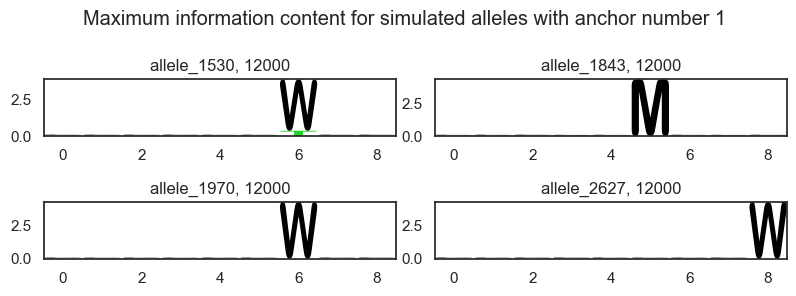

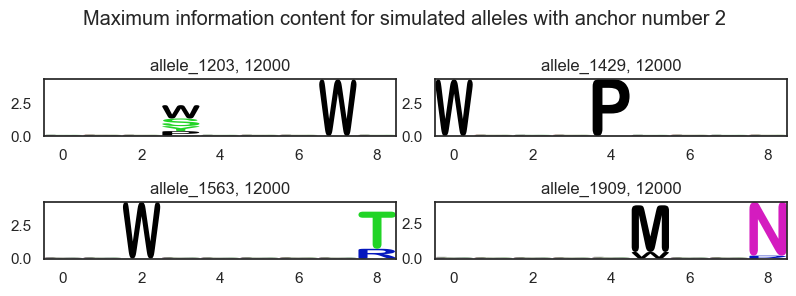

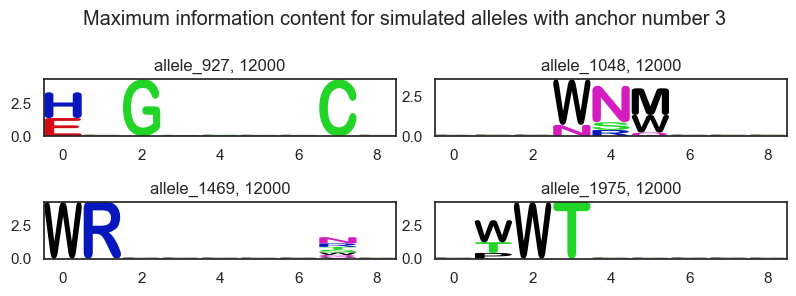

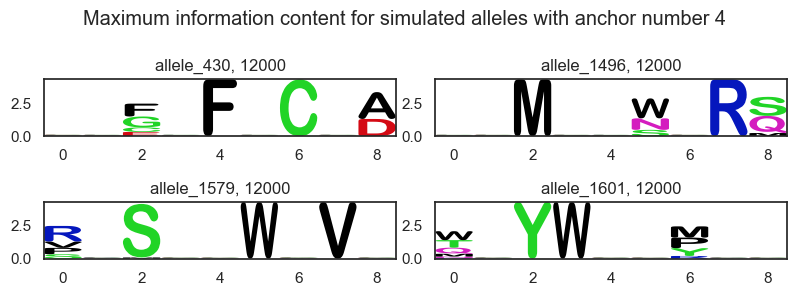

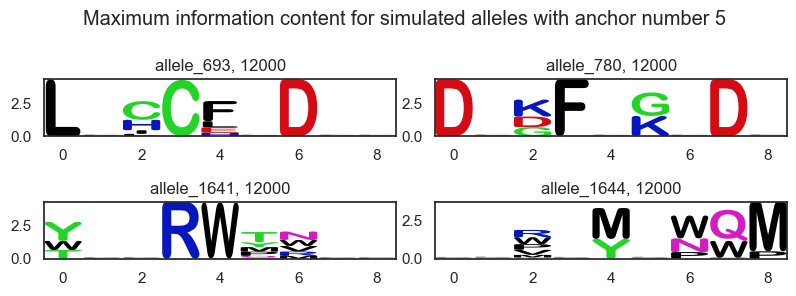

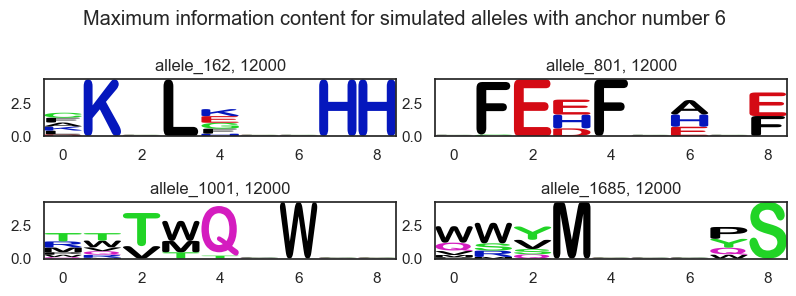

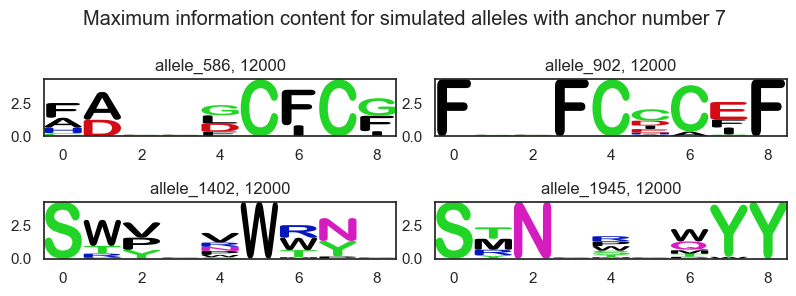

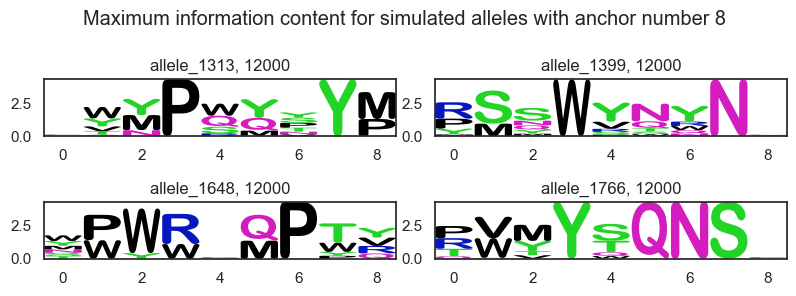

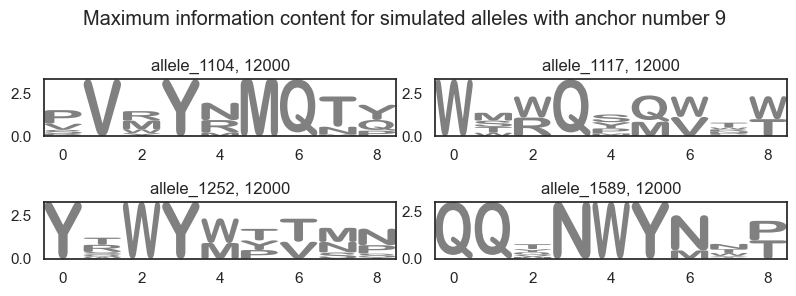

In [66]:
number_of_motifs = 4
minimal = False
for number_of_anchors in range(1,10):
    fig, axes = plt.subplots(nrows=int(number_of_motifs/2), ncols=2, figsize=(8, 3))
    tmp = simulated_annotation.copy()
    current_alleles_indexes = list(simulated_annotation[simulated_annotation.number_of_anchors == number_of_anchors].index_in_list)
    current_allele_names = np.array(simulated_alleles)[current_alleles_indexes]
    extremal_alleles = total_df[total_df.allele.isin(current_allele_names)].sort_values(by='mean_information', ascending=minimal).head(number_of_motifs).allele.values
    extremal_indexes = list(simulated_annotation[simulated_annotation.allele.isin(extremal_alleles)].index_in_list)
    for allele_index, ax_ind in zip(extremal_indexes, np.ndindex(axes.shape)):
        make_logo_for_data(motifs_sequences[allele_index], simulated_alleles[allele_index], ax=axes[ax_ind])
    first_word = "Minimal" if minimal else "Maximum"
    fig.suptitle(f"{first_word} information content for simulated alleles with anchor number {number_of_anchors}")
    plt.tight_layout()



## Calculate distances between alleles
Calculate distance as distance between emission matrices

In [76]:
from scipy.stats import wasserstein_distance


In [68]:
def get_distance(df1, df2):
    motif1 = df1.values
    motif2 =  df2.values
    cur_shape = motif1.shape
    cumulative_distance = 0
    for position in range(cur_shape[0]):
        cumulative_distance += wasserstein_distance(motif1[position,:],motif2[position,:])
    return cumulative_distance

In [69]:
real_distances = list()
from_list = list()
to_list = list()
for i in range(len(alleles_external)):
    for j in range(i):
        real_distances.append(get_distance(allele_to_matrix[alleles_external[i]], allele_to_matrix[alleles_external[j]]))
        from_list.append(i)
        to_list.append(j)

decoy_distances = list()
from_decoy_list = list()
to_decoy_list = list()
for i in range(len(alleles_decoy)):
    for j in range(i):
        decoy_distances.append(get_distance(decoy_allele_to_matrix[alleles_decoy[i]], decoy_allele_to_matrix[alleles_decoy[j]]))
        from_decoy_list.append(i)
        to_decoy_list.append(j)


mixed_distances = list()
from_mixed_list = list()
to_mixed_list = list()
for i in range(len(alleles_decoy)):
    for j in range(len(alleles_external)):
        mixed_distances.append(get_distance(decoy_allele_to_matrix[alleles_decoy[i]], allele_to_matrix[alleles_external[j]]))
        from_mixed_list.append(i)
        to_mixed_list.append(j)




df_distances_decoy = pd.DataFrame({"from": from_decoy_list, "to":to_decoy_list,"distance":decoy_distances, "allele_type":"decoy"})
df_distances_real = pd.DataFrame({"from": from_list, "to":to_list,"distance":real_distances, "allele_type":"real_data"})
df_distances_mixed = pd.DataFrame({"from": from_mixed_list, "to":to_mixed_list,"distance":mixed_distances, "allele_type":"mixed"})


In [70]:
df_total_distances = pd.concat([df_distances_real,df_distances_decoy,df_distances_mixed ])

Text(0.5, 1.0, 'Distances between motifs')

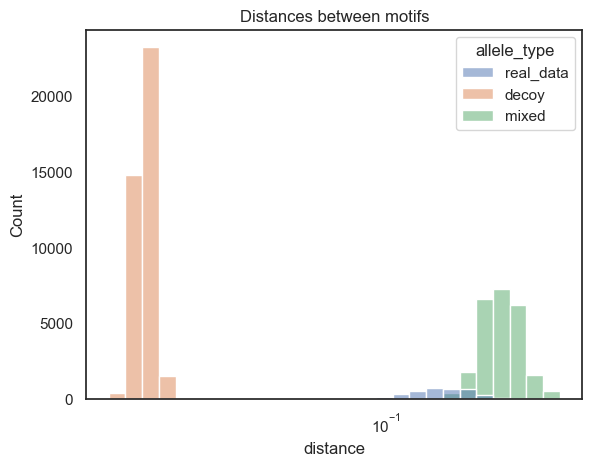

In [71]:
sns.histplot(df_total_distances, x='distance', hue='allele_type', log_scale=True,).set_title('Distances between motifs')

## Wasserstein distance is not a good example

In [41]:
# Generate two dummy motifs

motif1 = logomaker.alignment_to_matrix(['A'*9, 'C'*9,'D'*9], to_type='probability')
motif2 = logomaker.alignment_to_matrix(['E'*9, 'F'*9,'G'*9,], to_type='probability')

for column in natural_distribution_of_aas:
    if column not in motif1:
        motif1[column] = 1e-5

for column in natural_distribution_of_aas:
    if column not in motif2:
        motif2[column] = 1e-5
motif1 = motif1[natural_distribution_of_aas.columns]
motif2 = motif2[natural_distribution_of_aas.columns]


In [42]:
motif2[1:]

,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
pos,,,,,,,,,,,,,,,,,,,,
1,0.00001,0.00001,0.00001,0.333333,0.333333,0.333333,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001
2,0.00001,0.00001,0.00001,0.333333,0.333333,0.333333,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001
3,0.00001,0.00001,0.00001,0.333333,0.333333,0.333333,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001
4,0.00001,0.00001,0.00001,0.333333,0.333333,0.333333,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001
5,0.00001,0.00001,0.00001,0.333333,0.333333,0.333333,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001
6,0.00001,0.00001,0.00001,0.333333,0.333333,0.333333,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001
7,0.00001,0.00001,0.00001,0.333333,0.333333,0.333333,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001
8,0.00001,0.00001,0.00001,0.333333,0.333333,0.333333,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001,0.00001


In [43]:
get_distance(motif1, motif2)

0.0

## Jensen-Shannon

In [72]:
from scipy.spatial.distance import jensenshannon

def get_distance(dict_of_matrices, ind1, ind2):
    motif1 = dict_of_matrices[list(dict_of_matrices.keys())[ind1]].values
    motif2 = dict_of_matrices[list(dict_of_matrices.keys())[ind2]].values
    cur_shape = motif1.shape
    cumulative_distance = 0
    for position in range(cur_shape[0]):
        cumulative_distance += jensenshannon(motif1[position,:],motif2[position,:])
    return cumulative_distance/cur_shape[0]

def get_distance_old(df1, df2):
    motif1 = df1.values
    motif2 = df2.values
    cur_shape = motif1.shape
    cumulative_distance = 0
    for position in range(cur_shape[0]):
        cumulative_distance += jensenshannon(motif1[position,:],motif2[position,:])
    return cumulative_distance



In [73]:
def calculate_pairwise_distances_for_distributions(distribtuions_dict):
    vectorized_distance = np.vectorize(get_distance)
    triu_coordinates = np.triu_indices(len(distribtuions_dict),1)
    distances_array = vectorized_distance(distribtuions_dict, triu_coordinates[0], triu_coordinates[1])
    from_array =  triu_coordinates[0]
    to_array =  triu_coordinates[1]
    return distances_array, from_array, to_array

real_distances,  from_list, to_list = calculate_pairwise_distances_for_distributions(allele_to_matrix)
decoy_distances, from_decoy_list, to_decoy_list = calculate_pairwise_distances_for_distributions(decoy_allele_to_matrix)

mixed_dict = dict()
mixed_dict.update(allele_to_matrix)
mixed_dict.update(decoy_allele_to_matrix)
mixed_distances,  from_mixed_list, to_mixed_list = calculate_pairwise_distances_for_distributions(mixed_dict)

df_distances_decoy = pd.DataFrame({"from": from_decoy_list, "to":to_decoy_list,"distance":decoy_distances, "allele_type":"decoy"})
df_distances_real = pd.DataFrame({"from": from_list, "to":to_list,"distance":real_distances, "allele_type":"real_data"})
df_distances_mixed = pd.DataFrame({"from": from_mixed_list, "to":to_mixed_list,"distance":mixed_distances, "allele_type":"mixed"})

In [74]:
df_total_distances = pd.concat([df_distances_real,df_distances_decoy,df_distances_mixed ])

Text(0.5, 1.0, 'Distances between motifs')

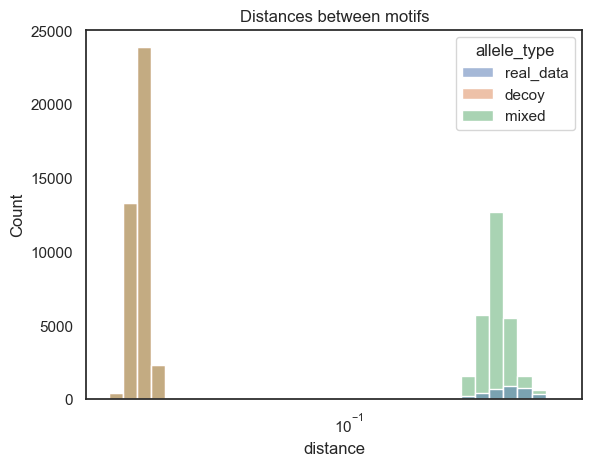

In [75]:
sns.histplot(df_total_distances, x='distance', hue='allele_type', log_scale=True,).set_title('Distances between motifs')

## Understand maximum distance

In [79]:
len(simulated_allele_to_matrix)

3000

In [80]:
%%time
def calculate_pairwise_distances_for_distributions(distribtuions_dict, alleles):
    vectorized_distance = np.vectorize(get_distance)
    triu_coordinates = np.triu_indices(len(distribtuions_dict),1)
    distances_array = vectorized_distance(distribtuions_dict, triu_coordinates[0], triu_coordinates[1])
    from_array =  triu_coordinates[0]
    to_array =  triu_coordinates[1]
    return distances_array, from_array, to_array

distances, from_list, to_list = calculate_pairwise_distances_for_distributions(simulated_allele_to_matrix, simulated_alleles)
df_distances_simulated = pd.DataFrame({"from": from_list, "to":to_list,"distance":distances, "allele_type":"simulated"})


CPU times: total: 23min 50s
Wall time: 24min 14s


In [81]:
df_distances_simulated.sort_values(by='distance')

,from,to,distance,allele_type
2668623,1086,1951,0.017273,simulated
1238600,446,728,0.017957,simulated
3874106,1882,1892,0.018659,simulated
2602941,1052,1872,0.018867,simulated
3830008,1843,2098,0.018949,simulated
...,...,...,...,...
2174019,843,1609,0.832555,simulated
1408115,513,1470,0.832555,simulated
1932678,734,1158,0.832555,simulated
1408112,513,1467,0.832555,simulated


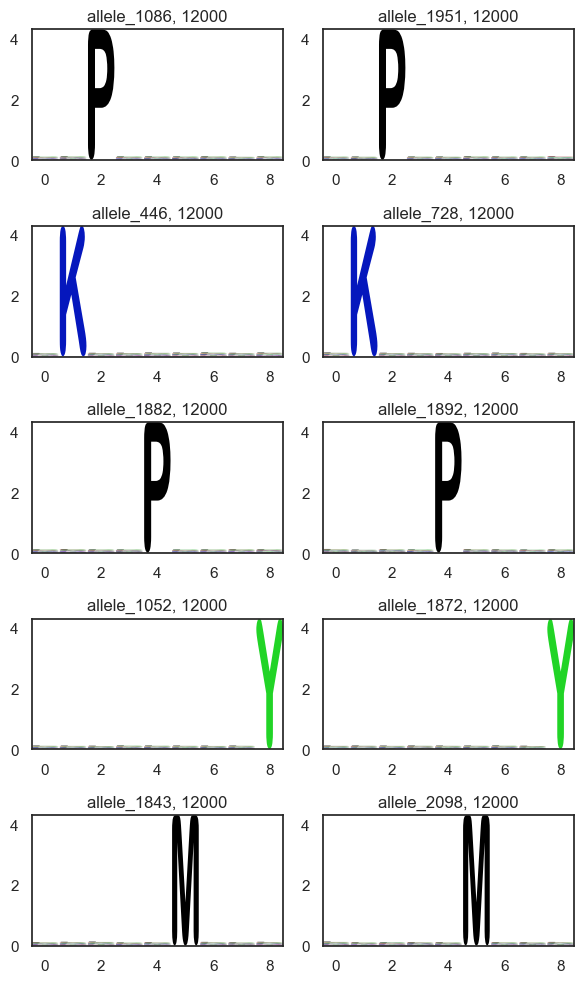

In [86]:
# lowest differences
sorted_distances = df_distances_simulated.sort_values(by='distance')

number_of_examples = 5

fig, axes = plt.subplots(nrows=number_of_examples, ncols=2, figsize=(6, 10))

for i, (idx, row) in enumerate(sorted_distances.head(number_of_examples).iterrows()):
    from_motif = row['from']
    to_motif = row['to']
    make_logo_for_data(motifs_sequences[from_motif], simulated_alleles[from_motif], ax=axes[i,0])
    make_logo_for_data(motifs_sequences[to_motif], simulated_alleles[to_motif], ax=axes[i,1])
plt.tight_layout()
# # Highest difference
# from_motif = df_distances_simulated.iloc[df_distances_simulated.distance.idxmax()]['from']
# to_motif = df_distances_simulated.iloc[df_distances_simulated.distance.idxmax()]['to']
# make_logo_for_data(motifs_sequences[to_motif], simulated_alleles[to_motif])
# make_logo_for_data(motifs_sequences[from_motif], simulated_alleles[from_motif])

In [89]:
len(sorted_distances)

4498500

Value sample:  668874    0.083232
Name: distance, dtype: float64


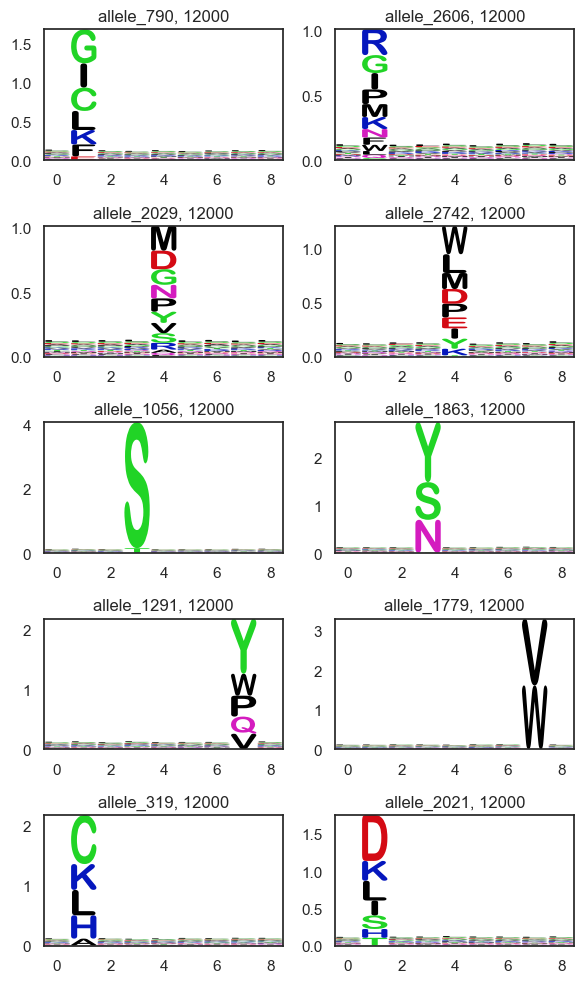

In [90]:
# specific percentile
percentile_value = 1
number_of_examples = 5
fig, axes = plt.subplots(nrows=number_of_examples, ncols=2, figsize=(6, 10))
sorted_distances['percentile'] = pd.qcut(sorted_distances['distance'], 10000, labels=False, duplicates='drop' )
print("Value sample: ", sorted_distances[sorted_distances.percentile == percentile_value].sample().distance)
for i, (idx, row) in enumerate(sorted_distances[sorted_distances.percentile == percentile_value].sample(number_of_examples).iterrows()):
    from_motif = row['from']
    to_motif = row['to']
    make_logo_for_data(motifs_sequences[from_motif], simulated_alleles[from_motif], ax=axes[i,0])
    make_logo_for_data(motifs_sequences[to_motif], simulated_alleles[to_motif], ax=axes[i,1])
plt.tight_layout()

In [142]:
sorted_distances[sorted_distances.percentile == 0]

,from,to,distance,allele_type,percentile
3504309,1589,2154,0.053312,simulated,0
1056778,375,2654,0.058506,simulated,0
790372,276,875,0.071168,simulated,0
3265545,1429,1710,0.072801,simulated,0
3307509,1456,1662,0.076187,simulated,0
...,...,...,...,...,...
3658782,1703,2442,0.147132,simulated,0
2134084,824,2809,0.147134,simulated,0
4344196,2443,2986,0.147135,simulated,0
4343696,2443,2486,0.147136,simulated,0


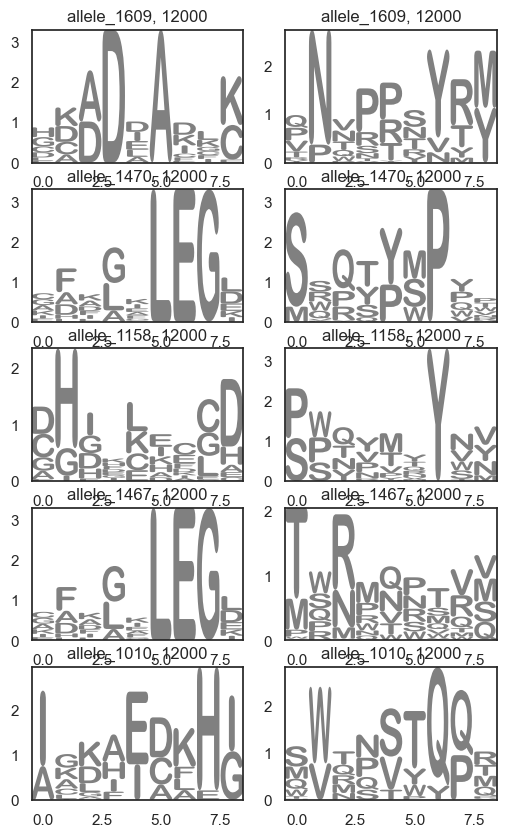

In [92]:
# maximum differences
sorted_distances = df_distances_simulated.sort_values(by='distance')

number_of_examples = 5

fig, axes = plt.subplots(nrows=number_of_examples, ncols=2, figsize=(6, 10))

for i, (idx, row) in enumerate(sorted_distances.tail(number_of_examples).iterrows()):
    from_motif = row['from']
    to_motif = row['to']
    make_logo_for_data(motifs_sequences[from_motif], simulated_alleles[to_motif], ax=axes[i,0])
    make_logo_for_data(motifs_sequences[to_motif], simulated_alleles[to_motif], ax=axes[i,1])



In [111]:
sorted_distances = df_distances_simulated.sample(50000).sort_values(by='distance').reset_index(drop=True)
#

<AxesSubplot: ylabel='distance'>

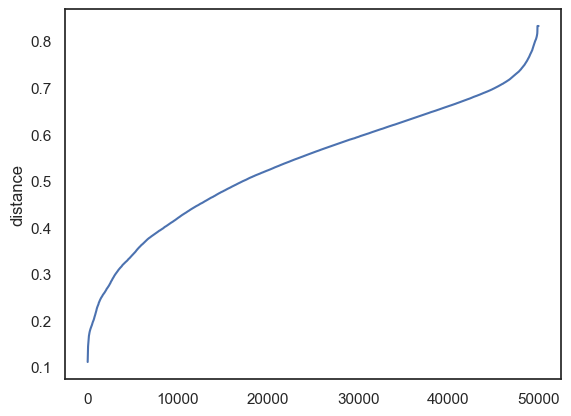

In [112]:
sns.lineplot(sorted_distances.distance)


In [103]:
df_total_distances = pd.concat([
    df_distances_real,
    df_distances_decoy,
    df_distances_mixed,
    df_distances_simulated.sample(n=100000) ])


Text(0.5, 1.0, 'Distances between motifs')

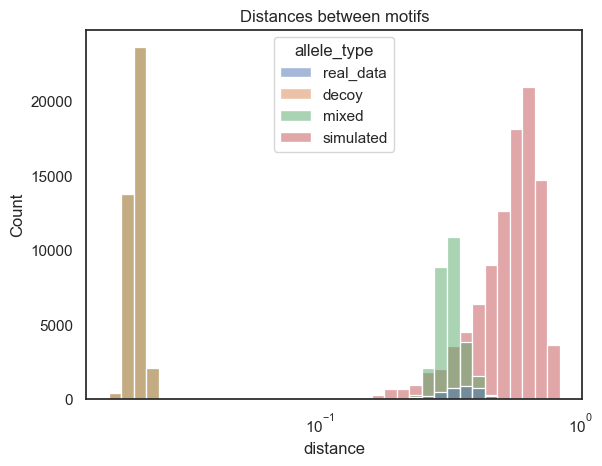

In [105]:
sns.histplot(df_total_distances, x='distance', hue='allele_type', log_scale=True,).set_title('Distances between motifs')


## How calculated info

In [48]:
SMALL = np.finfo(float).tiny
def _normalize_matrix(df):
    """
    Normalizes a matrix df to a probability matrix prob_df
    """

    # Check to see if values sum to one
    sums = df.sum(axis=1).values

    # Create normalized version of input matrix
    prob_df = df.copy()
    prob_df.loc[:, :] = df.values / sums[:, np.newaxis]

    # Validate and return probability matrix
    prob_df = logomaker.validate_matrix(prob_df, matrix_type='probability')
    return prob_df

def _get_background_mat(df, background):
    """
    Creates a background matrix given a background specification. There
    are three possiblities:

    1. background is None => out_df represents a uniform background
    2. background is a vector => this vector is normalized then used as
        the entries of the rows of out_df. Vector must be the same length
        as the number of columns in df
    3. background is a dataframe => it is then normalized and use as out_df.
        In this case, background must have the same rows and cols as df
    """

    # Get dimensions of df
    num_pos, num_cols = df.shape

    # Create background using df as template
    bg_df = df.copy()

    # If background is not specified, use uniform background
    if background is None:
        bg_df.loc[:, :] = 1 / num_cols

    # If background is array-like
    elif isinstance(background, (np.ndarray, list, tuple)):
        background = np.array(background)
        bg_df.loc[:, :] = background[np.newaxis, :]
        bg_df = _normalize_matrix(bg_df)

    # If background is a dataframe
    elif isinstance(background, pd.core.frame.DataFrame):
        bg_df = logomaker.validate_matrix(background)
        bg_df = _normalize_matrix(bg_df)

    # validate as probability matrix
    bg_df = logomaker.validate_matrix(bg_df, matrix_type='probability')
    return bg_df

def _probability_mat_to_information_mat(prob_df, background=None):
    """
    Converts a probability matrix to an information matrix
    """

    # Validate matrix before use
    prob_df = logomaker.validate_matrix(prob_df, matrix_type='probability')

    # Get background matrix
    bg_df = _get_background_mat(prob_df, background)

    # Compute info_df
    info_df = prob_df.copy()
    fg_vals = prob_df.values
    bg_vals = bg_df.values
    tmp_vals = fg_vals * (np.log2(fg_vals + SMALL) - np.log2(bg_vals + SMALL))
    info_vec = tmp_vals.sum(axis=1)
    info_df.loc[:, :] = fg_vals * info_vec[:, np.newaxis]

    # Validate and return
    info_df = logomaker.validate_matrix(info_df, matrix_type='information')
    return info_df


In [74]:
distribution = allele_to_matrix[alleles_external[0]].values

In [76]:
info_matrix = logomaker.transform_matrix(allele_to_matrix[alleles_external[0]], from_type='probability', to_type='information', background=natural_distribution_of_aas)
info_matrix.sum(axis=1)

pos
0    0.742299
1    0.276800
2    0.595458
3    2.005981
4    0.145298
5    0.969431
6    0.236401
7    0.130303
8    0.515400
dtype: float64

In [95]:
prob_df = _normalize_matrix(allele_to_matrix[alleles_external[0]])
bg_df = _get_background_mat(prob_df, natural_distribution_of_aas)
methods_info_matrix = _probability_mat_to_information_mat(prob_df, background=bg_df)
methods_info_matrix.sum(axis=1)

pos
0    0.742299
1    0.276800
2    0.595458
3    2.005981
4    0.145298
5    0.969431
6    0.236401
7    0.130303
8    0.515400
dtype: float64

In [96]:
df = allele_to_matrix[alleles_external[0]]
test_norm_df = df.copy()
sums = df.sum(axis=1).values
test_norm_df.loc[:, :] = df.values / sums[:, np.newaxis]

In [99]:
df

,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
pos,,,,,,,,,,,,,,,,,,,,
0,0.114629,0.003448,0.007210,0.035110,0.068025,0.013689,0.007732,0.118704,0.004180,0.089551,0.021212,0.002194,0.175444,0.009718,0.005329,0.019645,0.034169,0.165099,0.047649,0.057262
1,0.186207,0.000104,0.035110,0.057889,0.020899,0.093417,0.044619,0.026646,0.051829,0.030094,0.015465,0.044514,0.007210,0.064577,0.053710,0.109195,0.078265,0.044410,0.011181,0.024660
2,0.250679,0.005747,0.024033,0.027064,0.024138,0.226855,0.022048,0.011494,0.018600,0.027691,0.011808,0.027795,0.061024,0.024451,0.045455,0.104389,0.031452,0.022571,0.003344,0.029363
3,0.363323,0.001045,0.000522,0.001254,0.000522,0.411076,0.000209,0.004284,0.001567,0.000940,0.000209,0.000731,0.005434,0.001672,0.000313,0.173772,0.014107,0.016719,0.001567,0.000731
4,0.143678,0.000522,0.038349,0.084222,0.015569,0.051515,0.026332,0.042320,0.075967,0.082654,0.013166,0.031139,0.028527,0.053396,0.042842,0.070010,0.060397,0.109927,0.004702,0.024765
5,0.263009,0.016405,0.009300,0.007210,0.003030,0.042215,0.000731,0.081296,0.000940,0.051933,0.006061,0.002194,0.183804,0.004911,0.001776,0.082550,0.061338,0.180042,0.000209,0.001045
6,0.208673,0.005434,0.024556,0.085684,0.024869,0.070742,0.026750,0.031766,0.022153,0.051202,0.014211,0.052978,0.049112,0.079310,0.047753,0.089028,0.032915,0.054963,0.007941,0.019958
7,0.129258,0.000209,0.032497,0.071160,0.028318,0.078161,0.009613,0.042633,0.054232,0.077220,0.010240,0.029781,0.123406,0.031452,0.056531,0.083699,0.057785,0.050470,0.006374,0.026959
8,0.191014,0.019645,0.041902,0.023615,0.006583,0.137827,0.009404,0.058830,0.003344,0.032602,0.007628,0.054545,0.029676,0.021003,0.006897,0.147649,0.098433,0.099791,0.002717,0.006897


In [114]:
print(distribution.sum(axis=1) > 1)

[False False False  True  True False  True False False]


In [116]:
distr_matrix = prob_df.values
tmp_vals = (distr_matrix * (np.log2(distr_matrix + SMALL) - np.log2(bg_df.values + SMALL)))
info_vec = tmp_vals.sum(axis=1)
info_df = prob_df.copy()
info_df.loc[:, :] = distr_matrix * info_vec[:, np.newaxis]

In [115]:
info_vec

array([0.74229885, 0.2768002 , 0.59545829, 2.00598116, 0.14529821,
       0.96943136, 0.23640059, 0.1303027 , 0.51540019])

In [106]:
info_vec[:, np.newaxis]

array([[0.74229885],
       [0.2768002 ],
       [0.59545829],
       [2.00598116],
       [0.14529821],
       [0.96943136],
       [0.23640059],
       [0.1303027 ],
       [0.51540019]])

In [117]:
info_df

,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
pos,,,,,,,,,,,,,,,,,,,,
0,0.085089,0.002560,0.005352,0.026062,0.050495,0.010161,0.005740,0.088114,0.003103,0.066473,0.015746,0.001629,0.130232,0.007214,0.003956,0.014582,0.025364,0.122553,0.035370,0.042506
1,0.051542,0.000029,0.009718,0.016024,0.005785,0.025858,0.012350,0.007376,0.014346,0.008330,0.004281,0.012322,0.001996,0.017875,0.014867,0.030225,0.021664,0.012293,0.003095,0.006826
2,0.149269,0.003422,0.014311,0.016115,0.014373,0.135083,0.013129,0.006844,0.011075,0.016489,0.007031,0.016551,0.036337,0.014560,0.027066,0.062159,0.018729,0.013440,0.001991,0.017484
3,0.728819,0.002096,0.001048,0.002515,0.001048,0.824611,0.000419,0.008594,0.003144,0.001887,0.000419,0.001467,0.010900,0.003354,0.000629,0.348584,0.028298,0.033538,0.003144,0.001467
4,0.020876,0.000076,0.005572,0.012237,0.002262,0.007485,0.003826,0.006149,0.011038,0.012009,0.001913,0.004524,0.004145,0.007758,0.006225,0.010172,0.008776,0.015972,0.000683,0.003598
5,0.254970,0.015904,0.009016,0.006990,0.002938,0.040925,0.000709,0.078811,0.000912,0.050346,0.005875,0.002127,0.178185,0.004761,0.001722,0.080026,0.059463,0.174538,0.000203,0.001013
6,0.049330,0.001285,0.005805,0.020256,0.005879,0.016723,0.006324,0.007509,0.005237,0.012104,0.003360,0.012524,0.011610,0.018749,0.011289,0.021046,0.007781,0.012993,0.001877,0.004718
7,0.016843,0.000027,0.004234,0.009272,0.003690,0.010185,0.001253,0.005555,0.007067,0.010062,0.001334,0.003880,0.016080,0.004098,0.007366,0.010906,0.007530,0.006576,0.000831,0.003513
8,0.098448,0.010125,0.021596,0.012171,0.003393,0.071036,0.004847,0.030321,0.001723,0.016803,0.003931,0.028113,0.015295,0.010825,0.003554,0.076098,0.050732,0.051432,0.001400,0.003554


In [102]:
info_matrix

,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
pos,,,,,,,,,,,,,,,,,,,,
0,0.085089,0.002560,0.005352,0.026062,0.050495,0.010161,0.005740,0.088114,0.003103,0.066473,0.015746,0.001629,0.130232,0.007214,0.003956,0.014582,0.025364,0.122553,0.035370,0.042506
1,0.051542,0.000029,0.009718,0.016024,0.005785,0.025858,0.012350,0.007376,0.014346,0.008330,0.004281,0.012322,0.001996,0.017875,0.014867,0.030225,0.021664,0.012293,0.003095,0.006826
2,0.149269,0.003422,0.014311,0.016115,0.014373,0.135083,0.013129,0.006844,0.011075,0.016489,0.007031,0.016551,0.036337,0.014560,0.027066,0.062159,0.018729,0.013440,0.001991,0.017484
3,0.728819,0.002096,0.001048,0.002515,0.001048,0.824611,0.000419,0.008594,0.003144,0.001887,0.000419,0.001467,0.010900,0.003354,0.000629,0.348584,0.028298,0.033538,0.003144,0.001467
4,0.020876,0.000076,0.005572,0.012237,0.002262,0.007485,0.003826,0.006149,0.011038,0.012009,0.001913,0.004524,0.004145,0.007758,0.006225,0.010172,0.008776,0.015972,0.000683,0.003598
5,0.254970,0.015904,0.009016,0.006990,0.002938,0.040925,0.000709,0.078811,0.000912,0.050346,0.005875,0.002127,0.178185,0.004761,0.001722,0.080026,0.059463,0.174538,0.000203,0.001013
6,0.049330,0.001285,0.005805,0.020256,0.005879,0.016723,0.006324,0.007509,0.005237,0.012104,0.003360,0.012524,0.011610,0.018749,0.011289,0.021046,0.007781,0.012993,0.001877,0.004718
7,0.016843,0.000027,0.004234,0.009272,0.003690,0.010185,0.001253,0.005555,0.007067,0.010062,0.001334,0.003880,0.016080,0.004098,0.007366,0.010906,0.007530,0.006576,0.000831,0.003513
8,0.098448,0.010125,0.021596,0.012171,0.003393,0.071036,0.004847,0.030321,0.001723,0.016803,0.003931,0.028113,0.015295,0.010825,0.003554,0.076098,0.050732,0.051432,0.001400,0.003554


In [72]:
(np.log2(distr_matrix))

array([[ -3.1249554 ,  -8.17990909,  -7.11577875,  -4.83198579,
         -3.87778948,  -6.19088021,  -7.01484984,  -3.07455609,
         -7.90237511,  -3.48115182,  -5.55896729,  -8.83198579,
         -2.51091669,  -6.6851444 ,  -7.55187787,  -5.66971436,
         -4.87115638,  -2.59859437,  -4.3914132 ,  -4.12627113],
       [ -2.42502159, -13.22430321,  -4.83198579,  -4.11056104,
         -5.58044702,  -3.42017219,  -4.48621095,  -5.22994977,
         -4.2701069 ,  -5.05437821,  -6.01484984,  -4.48959359,
         -7.11577875,  -3.95284018,  -4.21867866,  -3.19501598,
         -3.6754813 ,  -4.49298418,  -6.48283622,  -5.34166016],
       [ -1.99608577,  -7.4429435 ,  -5.37881316,  -5.20749492,
         -5.37255417,  -2.1401592 ,  -5.50320402,  -6.4429435 ,
         -5.74856978,  -5.17445466,  -6.40412425,  -5.16902077,
         -4.03447865,  -5.35393849,  -4.45943162,  -3.25996234,
         -4.99068353,  -5.46941571,  -8.22430321,  -5.08987689],
       [ -1.46067586,  -9.90237511, -

In [81]:
allele_to_matrix[alleles_external[0]]

,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
pos,,,,,,,,,,,,,,,,,,,,
0,0.114629,0.003448,0.007210,0.035110,0.068025,0.013689,0.007732,0.118704,0.004180,0.089551,0.021212,0.002194,0.175444,0.009718,0.005329,0.019645,0.034169,0.165099,0.047649,0.057262
1,0.186207,0.000104,0.035110,0.057889,0.020899,0.093417,0.044619,0.026646,0.051829,0.030094,0.015465,0.044514,0.007210,0.064577,0.053710,0.109195,0.078265,0.044410,0.011181,0.024660
2,0.250679,0.005747,0.024033,0.027064,0.024138,0.226855,0.022048,0.011494,0.018600,0.027691,0.011808,0.027795,0.061024,0.024451,0.045455,0.104389,0.031452,0.022571,0.003344,0.029363
3,0.363323,0.001045,0.000522,0.001254,0.000522,0.411076,0.000209,0.004284,0.001567,0.000940,0.000209,0.000731,0.005434,0.001672,0.000313,0.173772,0.014107,0.016719,0.001567,0.000731
4,0.143678,0.000522,0.038349,0.084222,0.015569,0.051515,0.026332,0.042320,0.075967,0.082654,0.013166,0.031139,0.028527,0.053396,0.042842,0.070010,0.060397,0.109927,0.004702,0.024765
5,0.263009,0.016405,0.009300,0.007210,0.003030,0.042215,0.000731,0.081296,0.000940,0.051933,0.006061,0.002194,0.183804,0.004911,0.001776,0.082550,0.061338,0.180042,0.000209,0.001045
6,0.208673,0.005434,0.024556,0.085684,0.024869,0.070742,0.026750,0.031766,0.022153,0.051202,0.014211,0.052978,0.049112,0.079310,0.047753,0.089028,0.032915,0.054963,0.007941,0.019958
7,0.129258,0.000209,0.032497,0.071160,0.028318,0.078161,0.009613,0.042633,0.054232,0.077220,0.010240,0.029781,0.123406,0.031452,0.056531,0.083699,0.057785,0.050470,0.006374,0.026959
8,0.191014,0.019645,0.041902,0.023615,0.006583,0.137827,0.009404,0.058830,0.003344,0.032602,0.007628,0.054545,0.029676,0.021003,0.006897,0.147649,0.098433,0.099791,0.002717,0.006897


In [82]:
bg_df

,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
pos,,,,,,,,,,,,,,,,,,,,
0,0.066470,0.021098,0.047650,0.070905,0.035178,0.062337,0.025244,0.043243,0.057427,0.096161,0.048262,0.035963,0.059660,0.046936,0.054387,0.080709,0.052072,0.058573,0.011643,0.026081
1,0.072670,0.021394,0.049358,0.073551,0.035895,0.064253,0.025589,0.043923,0.058732,0.097830,0.020121,0.036813,0.061120,0.048146,0.055557,0.083785,0.052932,0.059797,0.012136,0.026400
2,0.069118,0.021588,0.048783,0.073203,0.036093,0.064614,0.025921,0.044076,0.058688,0.098571,0.020067,0.037057,0.061907,0.048493,0.056557,0.083373,0.053571,0.059865,0.012002,0.026451
3,0.068862,0.021655,0.048610,0.072794,0.036279,0.064313,0.025824,0.044254,0.059194,0.098881,0.019957,0.036961,0.062012,0.048469,0.056567,0.083277,0.053352,0.060036,0.012122,0.026580
4,0.068845,0.021720,0.048782,0.072919,0.036159,0.064450,0.025756,0.044398,0.059172,0.098939,0.020192,0.036688,0.061690,0.048499,0.056249,0.083137,0.053281,0.060281,0.012219,0.026624
5,0.068659,0.021726,0.048920,0.072867,0.036002,0.064652,0.025919,0.044235,0.059002,0.099314,0.020052,0.036728,0.061724,0.048412,0.056468,0.083329,0.053338,0.059835,0.012190,0.026628
6,0.068586,0.021613,0.048698,0.073018,0.036042,0.064504,0.026101,0.044385,0.058796,0.099350,0.020060,0.036957,0.061657,0.048323,0.056445,0.082763,0.053580,0.060264,0.012032,0.026825
7,0.068583,0.021718,0.048702,0.072810,0.036168,0.064363,0.026049,0.044105,0.058974,0.099163,0.020091,0.036816,0.061886,0.048507,0.056477,0.083116,0.053370,0.060089,0.012238,0.026777
8,0.068831,0.021862,0.048880,0.072515,0.036077,0.064294,0.026190,0.044410,0.058693,0.099245,0.020075,0.036795,0.061539,0.048605,0.056547,0.082922,0.053510,0.060297,0.012115,0.026599
